# Full-PolSAR Decomposition → Land-Cover Classification
### Reproducible proof of concept for a master's thesis in SAR / PolSAR phenology

**Scientific objective:** show how a full-polarimetric, multi-look coherency matrix $T_3$ can be converted into physically interpretable **Cloude–Pottier $H/A/\bar\alpha$** and Pauli features, and then into a simple land-cover **classification**.

**Two deliberately separate modes:**
1. **Synthetic experiment (runs immediately):** generate physically plausible *toy* full-PolSAR coherency matrices for surface-like, volume-like and dihedral-like scattering; train and evaluate a small Random Forest on an **independent synthetic scene**.
2. **Real-scene extension (optional):** load a real quad-pol $T_3$ product, decompose it and generate **unlabeled clusters**. Without field/reference labels, these clusters must **not** be described as validated land-cover classes.

> **Scientific integrity:** All numerical accuracy metrics in the default run come from synthetic data. They do **not** demonstrate performance on real imagery or phenology retrieval. The labels `Water-like`, `Vegetation-like`, and `Built-up-like` indicate *illustrative scattering archetypes*, not universal physical signatures.

A finished run exports figures and a machine-readable experiment report to `figures/`.

## 1 · Setup and experimental configuration

Install dependencies from the accompanying `requirements.txt` in a Python 3.10+ environment. Then run **Kernel → Restart & Run All**. No account, API key, commercial data, or network download is needed for the default synthetic experiment.

For **real imagery**, use a full quad-pol coherency product (`T3`) derived from genuinely calibrated and multilooked HH/HV/VH/VV data. **Sentinel-1 VV/VH alone cannot provide full $T_3$ or full-PolSAR $H/A/\alpha$.**

In [2]:
from pathlib import Path
import json
import re
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score, f1_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

SEED = 2026
N_LOOKS = 7             # synthetic multi-look complex Gaussian speckle
BOXCAR = 3              # 3x3 local averaging before decomposition
OUT = Path("figures")
OUT.mkdir(exist_ok=True, parents=True)
CLASS_NAMES = ["Water-like", "Vegetation-like", "Built-up-like"]
COLORS = ["#386a85", "#39866d", "#c57e4f"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "savefig.bbox": "tight"})
print("Mode: SYNTHETIC, with optional REAL T3 extension below")

Mode: SYNTHETIC, with optional REAL T3 extension below


## 2 · Physical model: reciprocal monostatic full-PolSAR

For a reciprocal monostatic system $S_{HV}\simeq S_{VH}$, the Pauli scattering vector is

$$
\mathbf{k}_p=\frac{1}{\sqrt 2}
\begin{bmatrix} S_{HH}+S_{VV} \\ S_{HH}-S_{VV} \\ 2S_{HV}\end{bmatrix},\qquad
\mathbf{T}_3=\langle \mathbf{k}_p\mathbf{k}_p^{H}\rangle.
$$

The three diagonal terms $T_{11}$, $T_{22}$, $T_{33}$ represent **Pauli channel powers** associated with co-pol sum, co-pol difference and cross-pol scattering. **These are not the Freeman–Durden surface/volume/double-bounce powers**; interpreting an individual Pauli component as a unique physical mechanism is an approximation.

### Cloude–Pottier eigen-decomposition

Write $\mathbf{T}_3=\mathbf{U}\operatorname{diag}(\lambda_1,\lambda_2,\lambda_3)\mathbf{U}^{H}$ with $\lambda_1\ge\lambda_2\ge\lambda_3\ge0$ and $p_i=\lambda_i/\sum_j\lambda_j$.

$$
H=-\sum_{i=1}^3 p_i\log_3 p_i, \quad
A=\frac{\lambda_2-\lambda_3}{\lambda_2+\lambda_3}, \quad
\bar\alpha=\sum_{i=1}^3 p_i\cos^{-1}\left(|u_{1i}|\right).
$$

Here $H$ is normalized polarimetric entropy, $A$ is anisotropy, and $\bar\alpha$ is an eigenvector-weighted angle (displayed in **degrees**). A low-entropy scattering process can be surface-like or dihedral-like depending on $\bar\alpha$; strongly distributed scattering often has higher $H$.

**References:** Cloude & Pottier (1997), DOI [10.1109/36.551935](https://doi.org/10.1109/36.551935); ESA [RADARSAT-2 Polarimetry Tutorial](https://step.esa.int/docs/tutorials/S1TBX%20Polarimetry%20with%20Radarsat-2%20Tutorial_v2.pdf).

In [3]:
def make_scene(seed: int, height=120, width=180):
    """Return spatial class map + simulated multi-look 3x3 coherency.

    Classes are intentionally *toy scattering archetypes*, not measured land cover.
    Independent random seeds generate different geometry and speckle realizations.
    """
    rng = np.random.default_rng(seed)
    y, x = np.indices((height, width))
    labels = np.ones((height, width), dtype=np.int8)  # vegetation-like background
    river_center = width * (0.19 + 0.05*np.sin(y/16. + seed))
    labels[np.abs(x-river_center) < (11 + 3*np.sin(y/20. + .3))] = 0
    urban = ((x > width*.58) & (y > height*.52))
    urban |= ((x > width*.73) & (y > height*.22) & (y < height*.43))
    urban |= ((x > width*.39) & (x < width*.51) & (y > height*.72))
    labels[urban] = 2
    # Archetypal Hermitian PSD coherency matrices in Pauli basis.
    # 0: low span + mainly co-pol sum, 1: diffuse multi-component, 2: co-pol difference.
    bases = np.array([np.diag([.32,.015,.010]),
                      np.diag([.80,.65,.57]),
                      np.diag([.20,2.35,.14])], dtype=np.complex128)
    T = np.empty((height, width, 3, 3), dtype=np.complex128)
    flat = T.reshape(-1,3,3)
    cls = labels.ravel()
    # Gaussian scattering-vector realizations -> multi-look sample coherency.
    # This is a complex Wishart *sampling model*, not an SAR image simulator.
    for k in range(3):
        mask = np.flatnonzero(cls == k)
        scale = rng.lognormal(mean=0, sigma=.62, size=len(mask))
        z = (rng.normal(size=(len(mask),N_LOOKS,3)) +
             1j*rng.normal(size=(len(mask),N_LOOKS,3)))/np.sqrt(2.)
        vectors = z @ np.linalg.cholesky(bases[k]).T
        cov = np.einsum('nli,nlj->nij', vectors, vectors.conj()) / N_LOOKS
        flat[mask] = cov * scale[:,None,None] + np.eye(3)[None]*.014
    return labels, T


def spatial_average_t3(T, window=3):
    """Average complex matrix elements spatially (PSD-preserving)."""
    if window <= 1:
        return T.copy()
    averaged = uniform_filter(T.real, size=(window,window,1,1),mode='reflect') + 1j*uniform_filter(T.imag,size=(window,window,1,1),mode='reflect')
    return (averaged + np.swapaxes(averaged.conj(),-1,-2)) / 2

train_labels, train_raw = make_scene(SEED)
test_labels, test_raw = make_scene(SEED + 591)
train_T3 = spatial_average_t3(train_raw, BOXCAR)
test_T3 = spatial_average_t3(test_raw, BOXCAR)
assert train_T3.shape[-2:] == (3,3)
assert np.max(np.abs(train_T3 - np.swapaxes(train_T3.conj(), -1,-2))) < 1e-10
assert np.linalg.eigvalsh(train_T3).min() > -1e-9
print("Independent synthetic train/test scenes:", train_labels.shape, test_labels.shape)

Independent synthetic train/test scenes: (120, 180) (120, 180)


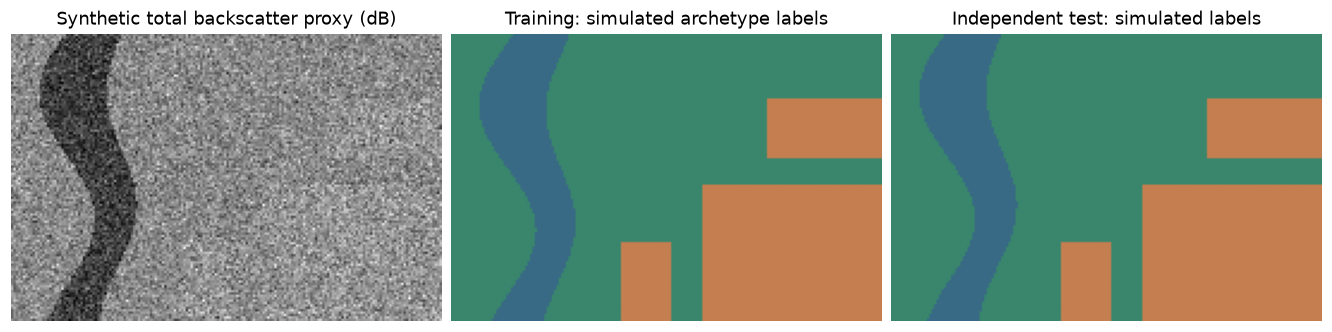

In [4]:
from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
axes[0].imshow(10*np.log10(np.maximum(np.trace(test_raw,axis1=-2,axis2=-1).real,1e-8)), cmap='gray')
axes[0].set_title('Synthetic total backscatter proxy (dB)')
axes[1].imshow(train_labels, cmap=ListedColormap(COLORS),vmin=-.5,vmax=2.5)
axes[1].set_title('Training: simulated archetype labels')
axes[2].imshow(test_labels, cmap=ListedColormap(COLORS),vmin=-.5,vmax=2.5)
axes[2].set_title('Independent test: simulated labels')
for a in axes: a.set_axis_off()
fig.savefig(OUT/'01_synthetic_inputs.png')
plt.show()

## 3 · Compute the physical polarimetric features

Implementation uses an eigen-decomposition of every Hermitian $T_3$. Pauli powers are normalized by total span to limit dependence on absolute scattering strength. This is **full-PolSAR** and is not applicable unchanged to typical dual-pol Sentinel-1 scenes.

In [5]:
def extract_features(T):
    """Return H, A, alpha[deg], Pauli normalized powers and log-span.

    Input shape (rows, columns, 3,3), Hermitian positive semidefinite.
    """
    T = np.asarray(T, dtype=np.complex128)
    if T.ndim != 4 or T.shape[-2:] != (3,3):
        raise ValueError("Expected a 2-D grid of full-pol T3 matrices: (H,W,3,3)")
    T = .5 * (T + np.swapaxes(T.conj(), -1, -2))
    valid = np.all(np.isfinite(T), axis=(-1,-2))
    safe_T = T.copy()
    safe_T[~valid] = np.eye(3) * 1e-8
    eigenvalues, eigvecs = np.linalg.eigh(safe_T)
    eigenvalues = np.clip(eigenvalues[..., ::-1], 0, None)
    eigvecs = eigvecs[..., ::-1]
    s = np.maximum(eigenvalues.sum(-1, keepdims=True), 1e-12)
    probs = eigenvalues/s
    entropy = -(np.where(probs>0,probs*np.log(np.maximum(probs,1e-12)),0).sum(-1))/np.log(3)
    anisotropy = (eigenvalues[...,1]-eigenvalues[...,2])/np.maximum(eigenvalues[...,1]+eigenvalues[...,2],1e-12)
    elemental_alpha = np.arccos(np.clip(np.abs(eigvecs[...,0,:]),0,1))
    alpha = np.rad2deg(np.sum(probs*elemental_alpha, axis=-1))
    span = np.maximum(np.real(np.trace(safe_T,axis1=-2,axis2=-1)),1e-12)
    pauli = np.real(np.diagonal(safe_T,axis1=-2,axis2=-1))/span[...,None]
    keys = ('H', 'A', 'alpha_deg', 'Pauli_1', 'Pauli_2', 'Pauli_3', 'log_span')
    maps = np.stack([entropy, anisotropy, alpha, pauli[...,0],pauli[...,1],pauli[...,2],np.log10(span)],axis=-1)
    maps[~valid] = np.nan
    return keys, maps

KEYS, train_features = extract_features(train_T3)
_, test_features = extract_features(test_T3)
assert np.all((test_features[...,0] >= -1e-7) & (test_features[...,0] <= 1+1e-7))
assert np.all((test_features[...,2] >= -1e-7) & (test_features[...,2] <= 90+1e-7))
print("Feature order:", KEYS)

Feature order: ('H', 'A', 'alpha_deg', 'Pauli_1', 'Pauli_2', 'Pauli_3', 'log_span')


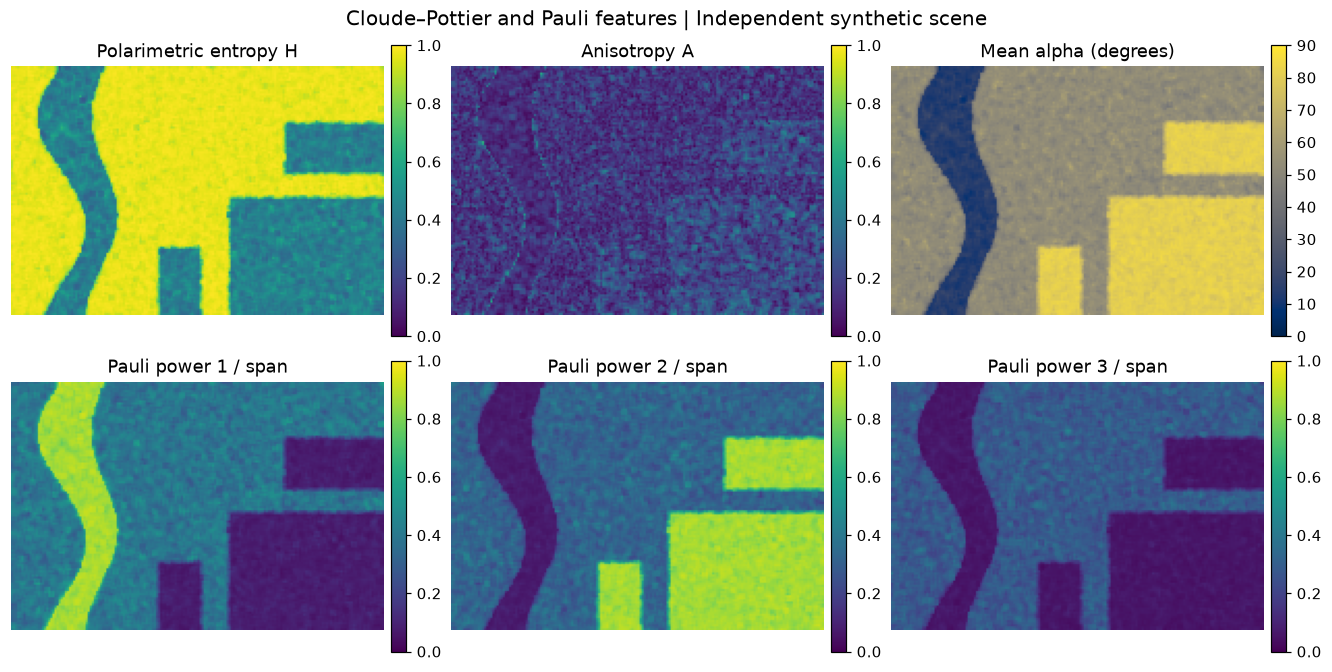

In [6]:
fig,axs=plt.subplots(2,3,figsize=(12,6),constrained_layout=True)
views = [(0,'Polarimetric entropy H','viridis',0,1),
         (1,'Anisotropy A','viridis',0,1),
         (2,'Mean alpha (degrees)','cividis',0,90),
         (3,'Pauli power 1 / span','viridis',0,1),
         (4,'Pauli power 2 / span','viridis',0,1),
         (5,'Pauli power 3 / span','viridis',0,1)]
for ax,(i,title,cmap,vmin,vmax) in zip(axs.flat,views):
    im=ax.imshow(test_features[...,i],cmap=cmap,vmin=vmin,vmax=vmax)
    ax.set_title(title)
    ax.axis('off')
    fig.colorbar(im,ax=ax,fraction=.046,pad=.02)
fig.suptitle('Cloude–Pottier and Pauli features | Independent synthetic scene',fontsize=13)
fig.savefig(OUT/'02_decomposition_features.png')
plt.show()

## 4 · Decomposition-based land-cover proxy classification

Compare a **single scalar backscatter/span feature** with **polarimetric decomposition features**. Both supervised classifiers use the simulated labels. Importantly, we train on one independently generated scene and test on another: **never split neighboring pixels randomly into train/test**, because spatial correlation creates overly optimistic estimates.

This is a controlled coding demonstration, **not** evidence of real-world classification performance.

In [7]:
def fitted_rf(features_train, features_test, cols, seed=SEED):
    model = RandomForestClassifier(n_estimators=90,min_samples_leaf=4,
                                   random_state=seed,n_jobs=-1,class_weight='balanced_subsample')
    model.fit(features_train[...,cols].reshape(-1,len(cols)),train_labels.ravel())
    pred = model.predict(features_test[...,cols].reshape(-1,len(cols)))
    return model,pred.reshape(test_labels.shape)

baseline, baseline_pred = fitted_rf(train_features,test_features,[6])
polmodel, polarimetric_pred = fitted_rf(train_features,test_features,[0,1,2,3,4,5,6])

def metrics(y,p):
    return dict(balanced_accuracy=float(balanced_accuracy_score(y.ravel(),p.ravel())),
                macro_f1=float(f1_score(y.ravel(),p.ravel(),average='macro')))
base_scores=metrics(test_labels,baseline_pred)
pol_scores=metrics(test_labels,polarimetric_pred)
print('Synthetic independent-scene evaluation (NOT real land-cover accuracy):')
print('Span only:',base_scores)
print('Full-PolSAR features:',pol_scores)
print('\nFull-polarimetry classification report:')
print(classification_report(test_labels.ravel(),polarimetric_pred.ravel(),target_names=CLASS_NAMES,digits=3))

Synthetic independent-scene evaluation (NOT real land-cover accuracy):
Span only: {'balanced_accuracy': 0.7583299034310248, 'macro_f1': 0.7529615406915267}
Full-PolSAR features: {'balanced_accuracy': 0.9907772112518803, 'macro_f1': 0.990548345759482}

Full-polarimetry classification report:
                 precision    recall  f1-score   support

     Water-like      0.984     0.984     0.984      2636
Vegetation-like      0.994     0.993     0.994     12796
  Built-up-like      0.992     0.995     0.994      6168

       accuracy                          0.993     21600
      macro avg      0.990     0.991     0.991     21600
   weighted avg      0.993     0.993     0.993     21600



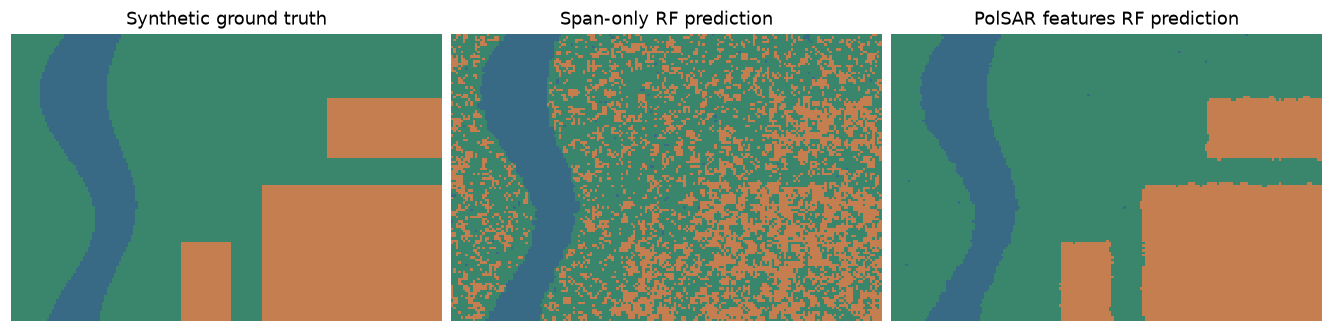

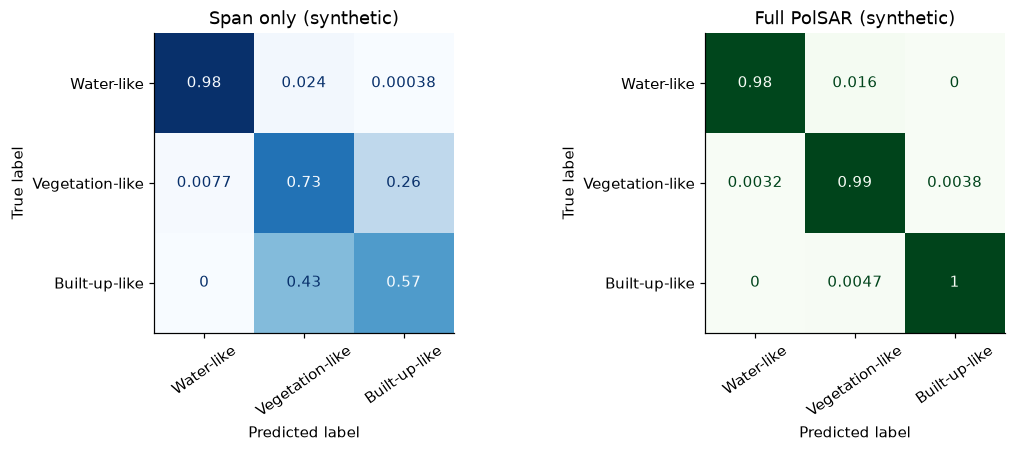

In [8]:
fig,axs=plt.subplots(1,3,figsize=(12,3.65),constrained_layout=True)
for ax,z,title in zip(axs,[test_labels,baseline_pred,polarimetric_pred],
                      ['Synthetic ground truth','Span-only RF prediction','PolSAR features RF prediction']):
    ax.imshow(z,cmap=ListedColormap(COLORS),vmin=-.5,vmax=2.5,interpolation='nearest')
    ax.set_title(title)
    ax.set_axis_off()
fig.savefig(OUT/'03_classification_comparison.png')
plt.show()
fig,axs=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(test_labels.ravel(),baseline_pred.ravel(),
    display_labels=CLASS_NAMES,normalize='true',ax=axs[0],cmap='Blues',colorbar=False)
axs[0].set_title('Span only (synthetic)')
ConfusionMatrixDisplay.from_predictions(test_labels.ravel(),polarimetric_pred.ravel(),
    display_labels=CLASS_NAMES,normalize='true',ax=axs[1],cmap='Greens',colorbar=False)
axs[1].set_title('Full PolSAR (synthetic)')
for a in axs: a.tick_params(axis='x',rotation=35)
fig.savefig(OUT/'04_synthetic_confusion_matrices.png')
plt.show()

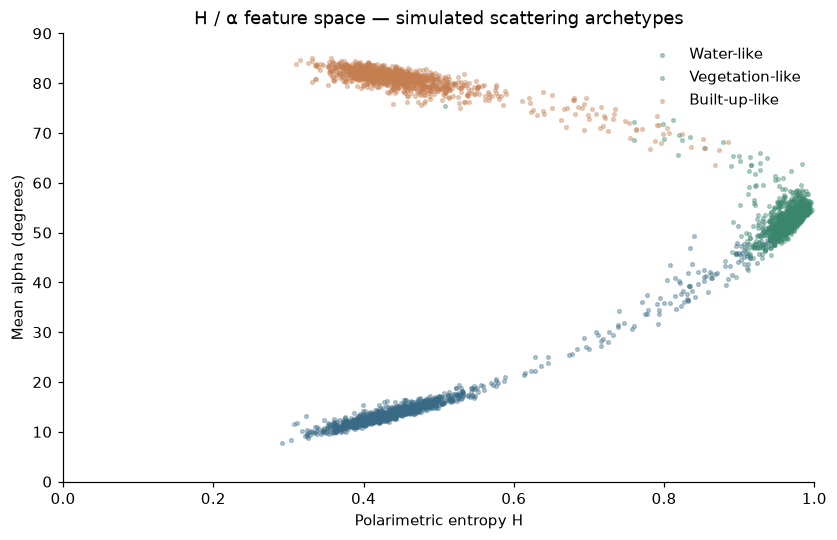

In [9]:
fig, ax=plt.subplots(figsize=(7.5,4.8),constrained_layout=True)
rng = np.random.default_rng(SEED+10)
for cls,name,color in zip(range(3),CLASS_NAMES,COLORS):
    ixs=np.flatnonzero(test_labels.ravel()==cls)
    subset=rng.choice(ixs,size=min(1100,len(ixs)),replace=False)
    pts=test_features.reshape(-1,len(KEYS))[subset]
    ax.scatter(pts[:,0],pts[:,2],s=6,c=color,alpha=.35,label=name,rasterized=True)
ax.set(xlabel='Polarimetric entropy H',ylabel='Mean alpha (degrees)',
       xlim=(0,1),ylim=(0,90),title='H / α feature space — simulated scattering archetypes')
ax.legend(frameon=False,loc='upper right')
fig.savefig(OUT/'05_h_alpha_scatter.png')
plt.show()

## 5 · Optional: run the **same decomposition** on a real full-PolSAR $T_3$

Set `REAL_T3_PATH` below to either:

- A `.npz` file with a complex Hermitian array under the `T3` key, shape `(rows, cols, 3, 3)`; or
- A directory with nine standard **PolSARpro $T_3$** float32 rasters (`T11.bin`, `T22.bin`, `T33.bin`, `T12_real.bin`, `T12_imag.bin`, etc.) and a matching `T11.hdr` in ENVI syntax, with `samples`, `lines`, `data type = 4`, `interleave = bsq`, and appropriate byte order.

A small subset is loaded for memory safety. A **real scene cannot be objectively classified into 'water / vegetation / urban' without reference labels**. The optional demonstration applies K-means to identify *unlabeled polarimetric clusters*, which can then be compared manually with independent optical maps. K-means is **not** a Wishart classifier.

Acquiring and calibrating RADARSAT-2 or ALOS PALSAR full-pol data is a separate prerequisite. The [ESA SNAP tutorial](https://step.esa.int/docs/tutorials/S1TBX%20Polarimetry%20with%20Radarsat-2%20Tutorial_v2.pdf) shows a real-data preparation workflow. [PyPolSARpro](https://polsarpro.readthedocs.io/en/latest/) and [PolSARtools](https://github.com/polsartools/polsartools) offer production-oriented decomposition/classification methods for follow-up work.

In [10]:
REAL_T3_PATH = None   # e.g. "data/real_T3.npz" or "data/T3/"
REAL_SUBSET_ROWS = 300
REAL_SUBSET_COLS = 400

def load_real_t3(path, rows=300, cols=400):
    """Load a small real T3 subset in NPZ or standard PolSARpro ENVI-BSQ float32."""
    p=Path(path)
    if p.is_file() and p.suffix.lower()=='.npz':
        with np.load(p) as data:
            if 'T3' not in data:
                raise KeyError("NPZ must contain a complex (rows,cols,3,3) array named T3")
            matrix=data['T3'][:rows,:cols].astype(np.complex128)
        if matrix.ndim != 4 or matrix.shape[-2:]!=(3,3):
            raise ValueError("T3 must have shape (rows,cols,3,3)")
        return matrix
    if not p.is_dir():
        raise FileNotFoundError(f"Expected a .npz or T3 folder: {p}")
    header=(p/'T11.hdr')
    if not header.exists():
        raise FileNotFoundError("Expected T11.hdr: provide PolSARpro-style ENVI T3 rasters")
    h=header.read_text(errors='replace')
    def field(name):
        m=re.search(r'^\s*'+re.escape(name)+r'\s*=\s*(\d+)',h,re.I|re.M)
        if not m: raise ValueError(f"ENVI header missing '{name}'")
        return int(m.group(1))
    nrows,ncols=field('lines'),field('samples')
    if field('data type')!=4:
        raise ValueError('Only ENVI data type 4 (float32) supported')
    order=int(re.search(r'byte order\s*=\s*(\d+)',h,re.I).group(1)) if re.search(r'byte order\s*=\s*(\d+)',h,re.I) else 0
    if re.search(r'interleave\s*=\s*([^\s}]+)',h,re.I) and re.search(r'interleave\s*=\s*([^\s}]+)',h,re.I).group(1).lower() != 'bsq':
        raise ValueError('Only BSQ interleave supported')
    dt=np.dtype('<f4' if order==0 else '>f4')
    def get(name):
        fp=p/(name+'.bin')
        arr=np.memmap(fp,dtype=dt,mode='r',shape=(nrows,ncols))
        return np.array(arr[:min(rows,nrows),:min(cols,ncols)],dtype=np.float64)
    diag=[get('T11'),get('T22'),get('T33')]
    n,m=diag[0].shape
    T=np.zeros((n,m,3,3),dtype=np.complex128)
    for j in range(3): T[...,j,j]=diag[j]
    for a,b in [(1,2),(1,3),(2,3)]:
        item=get(f'T{a}{b}_real')+1j*get(f'T{a}{b}_imag')
        T[...,a-1,b-1]=item
        T[...,b-1,a-1]=item.conj()
    return T

if REAL_T3_PATH is None:
    print('No real data provided. Skipping real-scene clustering; synthetic results above remain valid as a toy demonstration.')
else:
    real = load_real_t3(REAL_T3_PATH,REAL_SUBSET_ROWS,REAL_SUBSET_COLS)
    real = spatial_average_t3(real,BOXCAR)
    _, real_features=extract_features(real)
    good = np.isfinite(real_features).all(axis=-1)
    if good.sum()<100: raise ValueError('Too few valid real T3 pixels')
    X=real_features[good]
    scaler=StandardScaler().fit(X)
    km=KMeans(n_clusters=4,random_state=SEED,n_init=10).fit(scaler.transform(X))
    cluster_map=np.full(good.shape,np.nan)
    cluster_map[good]=km.labels_
    fig, ax=plt.subplots(1,3,figsize=(12,4),constrained_layout=True)
    ax[0].imshow(real_features[...,0],vmin=0,vmax=1,cmap='viridis');ax[0].set_title('Real: H')
    ax[1].imshow(real_features[...,2],vmin=0,vmax=90,cmap='cividis');ax[1].set_title('Real: mean α')
    ax[2].imshow(cluster_map,cmap='tab10',vmin=0,vmax=3);ax[2].set_title('Real: UNLABELED K-means clusters')
    for a in ax: a.axis('off')
    fig.savefig(OUT/'06_real_scene_unlabeled_clusters.png')
    plt.show()
    print('Real-scene clustering computed. No land-cover accuracy reported without independent reference labels.')

No real data provided. Skipping real-scene clustering; synthetic results above remain valid as a toy demonstration.


## 6 · Reproducibility report and interpretation

The next cell writes `figures/experiment_report.json`, including parameters, results and an explicit synthetic-data disclaimer. These outputs are intended as a short, reproducible demonstration for the supervisor, not as an empirical performance claim.

In [11]:
report = {
    'title':'Full-PolSAR H/A/alpha decomposition and toy land-cover classification',
    'data_mode':'synthetic multi-look coherency matrices',
    'scientific_warning':'Toy simulated scattering archetypes, not a real remote-sensing accuracy assessment',
    'random_seed':SEED,'synthetic_looks':N_LOOKS,'spatial_average_window':BOXCAR,
    'train_scene_shape':list(train_labels.shape),'test_scene_shape':list(test_labels.shape),
    'feature_names':list(KEYS), 'class_names':CLASS_NAMES,
    'independent_synthetic_test_scores': {'span_only':base_scores,'full_polsar':pol_scores},
    'real_t3_path':str(REAL_T3_PATH) if REAL_T3_PATH is not None else None,
    'real_data_note':'Only unlabeled clusters were produced if real data provided; no accuracy without reference labels.'
}
(OUT/'experiment_report.json').write_text(json.dumps(report,indent=2)+'\n')
print('Exported PNG figures +',OUT/'experiment_report.json')
print('Core result:')
print(' - Span-only macro F1:',round(base_scores['macro_f1'],3))
print(' - Full-PolSAR macro F1:',round(pol_scores['macro_f1'],3))
print(' - These are synthetic-only scores; do not cite as real land-cover classification performance.')

Exported PNG figures + figures/experiment_report.json
Core result:
 - Span-only macro F1: 0.753
 - Full-PolSAR macro F1: 0.991
 - These are synthetic-only scores; do not cite as real land-cover classification performance.


## 7 · Next experiment: from land-cover separability to crop phenology

The completed pipeline demonstrates how full-PolSAR scattering information can be turned into interpretable features and classifications. It **does not estimate BBCH phenological stages**. To move toward the thesis goal:

1. Acquire **calibrated full-pol** observations of agricultural fields with documented sensor frequency, polarization, incidence angle and acquisition dates.
2. Align observations and field-level **BBCH reference measurements**, not just crop-type labels.
3. Compare intensity-only features, Pauli/H/A/α descriptors, and—optionally—model-based Freeman–Durden scattering powers.
4. Control for spatial and temporal leakage: **held-out fields/seasons**, class imbalance and stage-specific error.
5. Compare classical ML to temporal learning models only after establishing well-calibrated reference data.

**Important distinctions:**
- Pauli power coloring ≠ Freeman–Durden three-component decomposition.
- An H/A/α feature-space map ≠ a validated land-cover map.
- Stage classification ≠ stage-onset date prediction.
- Full PolSAR ≠ standard Sentinel-1 VV/VH dual polarization.

### Selected references

- Cloude, S. R. & Pottier, E. (1997). *An entropy based classification scheme for land applications of polarimetric SAR*. IEEE TGRS, 35(1), 68–78. [DOI](https://doi.org/10.1109/36.551935).
- Freeman, A. & Durden, S. L. (1998). *A three-component scattering model for polarimetric SAR data*. IEEE TGRS, 36(3), 963–973. [DOI](https://doi.org/10.1109/36.673687).
- ESA, *RADARSAT-2 Polarimetry with SNAP* [official tutorial](https://step.esa.int/docs/tutorials/S1TBX%20Polarimetry%20with%20Radarsat-2%20Tutorial_v2.pdf).
- [PyPolSARpro documentation](https://polsarpro.readthedocs.io/en/latest/) (2026 Python PolSAR decomposition and Wishart-classification implementation).
- [PolSARtools project](https://github.com/polsartools/polsartools) (Python, T3/C3/GSLC processing).